# Taller — Comparación de modelos de regresión y clasificación
**Ciencia de Datos · Sesión 1 · Técnico en Ciencia de Datos**

**Objetivo:** comparar modelos supervisados a partir de métricas apropiadas y justificar su uso. Trabajaremos con **dos problemas independientes y datos sintéticos**. Las variables representan información disponible *antes* del evento que queremos predecir.

**Entrega:** notebook `.ipynb` ejecutable con tablas, gráficos y respuestas breves (2–3 líneas por pregunta). Sigue la guía `.tex` del taller.


**Versión estudiante: completa únicamente las celdas marcadas TODO.**

## 0. Preparación
Ejecuta la siguiente celda. XGBoost y CatBoost son **opcionales**; si alguna biblioteca no está instalada, continúa con los modelos disponibles. En Google Colab puedes instalarlas previamente con `!pip install -q xgboost catboost`.

In [7]:
!pip install -q xgboost catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.3 MB/s eta 0:00:00


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
try:
    from xgboost import XGBRegressor, XGBClassifier
except ImportError:
    XGBRegressor = XGBClassifier = None
try:
    from catboost import CatBoostRegressor, CatBoostClassifier
except ImportError:
    CatBoostRegressor = CatBoostClassifier = None

plt.rcParams.update({'figure.figsize': (7, 4.5), 'axes.grid': True})
print('XGBoost:', XGBRegressor is not None, '| CatBoost:', CatBoostRegressor is not None)

XGBoost: True | CatBoost: True


### Carga de los dos archivos CSV
Coloca los archivos CSV en la misma carpeta del notebook. Si usas Google Colab, la celda solicitará subirlos cuando no los encuentre. No utilices las variables objetivo como predictoras.

In [10]:
archivo_reg = 'taller_regresion_bicicletas.csv'
archivo_cls = 'taller_clasificacion_entregas.csv'
if not (Path(archivo_reg).exists() and Path(archivo_cls).exists()):
    try:
        from google.colab import files
        print('Sube los dos CSV descargados con el taller.')
        files.upload()
    except ImportError:
        raise FileNotFoundError('Ubica ambos CSV en la carpeta actual y ejecuta nuevamente.')

df_reg = pd.read_csv(archivo_reg)
df_cls = pd.read_csv(archivo_cls)
print('REGRESIÓN:', df_reg.shape)
display(df_reg.head())
print('CLASIFICACIÓN:', df_cls.shape)
display(df_cls.head())

REGRESIÓN: (650, 3)


,temperatura_c,lluvia_mm_h,bicicletas_siguiente_hora
0,12.65,0.67,182
1,24.64,2.96,201
2,20.15,4.43,170
3,17.63,3.62,179
4,17.23,7.66,128


CLASIFICACIÓN: (750, 3)


,distancia_km,congestion_indice,entrega_tardia
0,2.32,3.71,0
1,17.44,5.01,0
2,5.30,5.96,0
3,21.92,4.54,0
4,19.95,6.48,1


## Ejercicio 1 — Regresión: demanda de bicicletas
Una plataforma de bicicletas públicas busca pronosticar cuántas bicicletas serán utilizadas **durante la próxima hora**. Antes de esa hora conoce dos variables:

- `temperatura_c` (°C) y `lluvia_mm_h` (mm/h): **X**.
- `bicicletas_siguiente_hora` (cantidad): **Y**, objetivo continuo.
- **T**: predicción para la **próxima hora**.

### Tarea 1A. Exploración breve (5–10 min)
Revisa las distribuciones y representa con dispersión una de las relaciones X–Y. ¿Sugiere una forma lineal o no lineal? ¿Se observan variaciones en la dispersión?

,Variable,Rol,Unidad,Momento (T)
0,temperatura_c,X1 · predictor,°C,hora actual
1,lluvia_mm_h,X2 · predictor,mm/h,hora actual
2,bicicletas_siguiente_hora,Y · objetivo continuo,bicicletas,hora siguiente (horizonte de 1 h)


Tipos de dato y valores faltantes:


,tipo,faltantes
temperatura_c,float64,0
lluvia_mm_h,float64,0
bicicletas_siguiente_hora,int64,0


Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
temperatura_c,650.0,21.31,7.34,8.05,15.29,21.44,27.58,33.99
lluvia_mm_h,650.0,3.52,2.59,0.04,1.58,2.88,4.81,15.00
bicicletas_siguiente_hora,650.0,183.97,42.90,20.00,156.00,189.00,218.75,270.00


Correlación de Pearson con Y:


,bicicletas_siguiente_hora
temperatura_c,0.667
lluvia_mm_h,-0.677
bicicletas_siguiente_hora,1.000


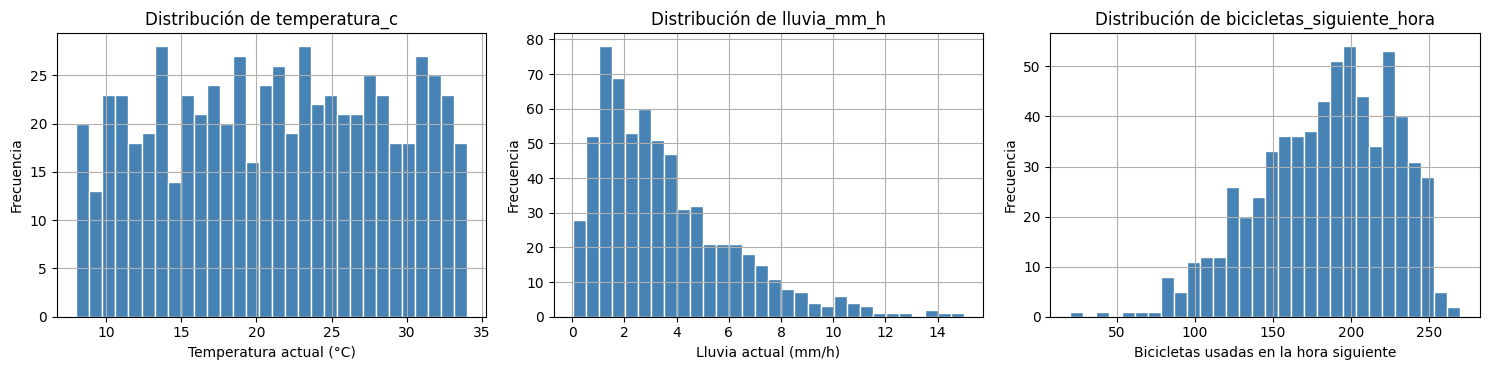

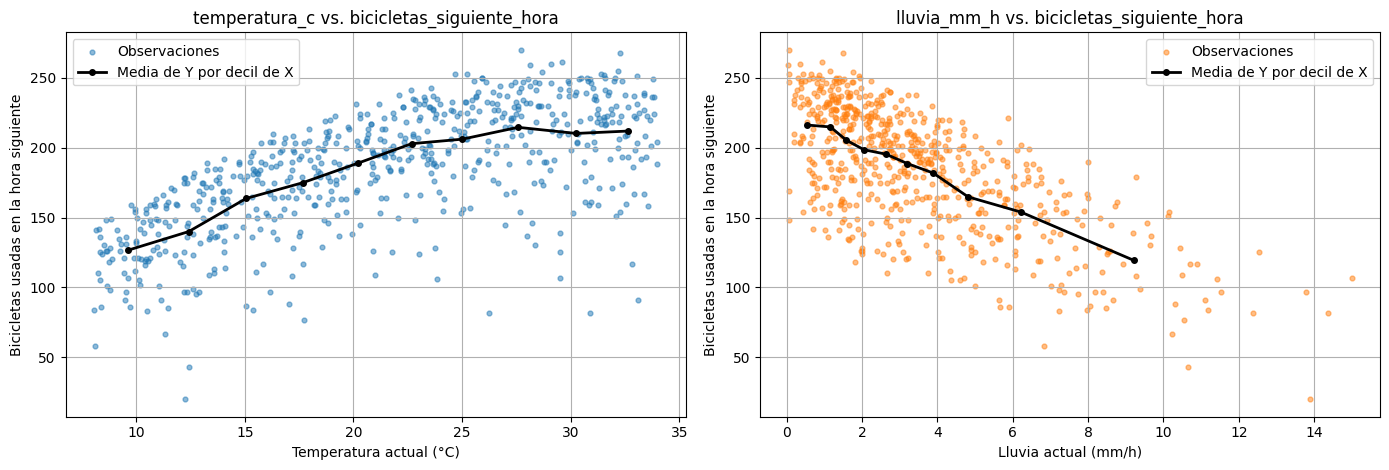

Media y dispersión de Y por quintil de temperatura:


,n,media,desviacion
temperatura_c,,,
"(8.049000000000001, 13.662]",130,133.3,30.1
"(13.662, 18.842]",130,169.3,29.7
"(18.842, 23.68]",130,195.9,27.2
"(23.68, 28.734]",130,210.3,33.1
"(28.734, 33.99]",130,211.0,35.5


In [11]:
# Descripción de X, Y y T en el problema de regresión
predictores_reg = ['temperatura_c', 'lluvia_mm_h']
objetivo_reg = 'bicicletas_siguiente_hora'
etiquetas_reg = {'temperatura_c': 'Temperatura actual (°C)',
                 'lluvia_mm_h': 'Lluvia actual (mm/h)',
                 'bicicletas_siguiente_hora': 'Bicicletas usadas en la hora siguiente'}

roles_reg = pd.DataFrame({
    'Variable': predictores_reg + [objetivo_reg],
    'Rol': ['X1 · predictor', 'X2 · predictor', 'Y · objetivo continuo'],
    'Unidad': ['°C', 'mm/h', 'bicicletas'],
    'Momento (T)': ['hora actual', 'hora actual', 'hora siguiente (horizonte de 1 h)']
})
display(roles_reg)

print('Tipos de dato y valores faltantes:')
display(pd.DataFrame({'tipo': df_reg.dtypes.astype(str), 'faltantes': df_reg.isna().sum()}))
print('Estadísticas descriptivas:')
display(df_reg.describe().T.round(2))
print('Correlación de Pearson con Y:')
display(df_reg.corr()[[objetivo_reg]].round(3))

# Distribuciones de X e Y
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, df_reg.columns):
    ax.hist(df_reg[col], bins=30, color='steelblue', edgecolor='white')
    ax.set_xlabel(etiquetas_reg[col])
    ax.set_ylabel('Frecuencia')
    ax.set_title(f'Distribución de {col}')
plt.tight_layout()
plt.show()

# Dispersión X–Y con la media de Y por decil de X (ayuda a ver curvatura)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, col, color in zip(axes, predictores_reg, ['tab:blue', 'tab:orange']):
    ax.scatter(df_reg[col], df_reg[objetivo_reg], s=12, alpha=0.5, color=color, label='Observaciones')
    medias = (df_reg.groupby(pd.qcut(df_reg[col], q=10), observed=True)
              .agg(x=(col, 'mean'), y=(objetivo_reg, 'mean')))
    ax.plot(medias['x'], medias['y'], 'k-o', lw=2, ms=4, label='Media de Y por decil de X')
    ax.set_xlabel(etiquetas_reg[col])
    ax.set_ylabel(etiquetas_reg[objetivo_reg])
    ax.set_title(f'{col} vs. {objetivo_reg}')
    ax.legend()
plt.tight_layout()
plt.show()

print('Media y dispersión de Y por quintil de temperatura:')
display(df_reg.groupby(pd.qcut(df_reg['temperatura_c'], q=5), observed=True)[objetivo_reg]
        .agg(n='size', media='mean', desviacion='std').round(1))

**Observación 1A:** X (temperatura y lluvia) se mide en la hora actual e Y es la demanda de la hora siguiente (T = 1 h), así que los predictores están disponibles antes del evento; hay 650 registros sin valores faltantes. La relación **temperatura–demanda presenta curvatura**: la media de Y sube rápido de ≈127 bicicletas cerca de 10 °C a ≈200 hacia 23 °C y luego se aplana en ≈210–215 sobre 27 °C (forma cóncava, de saturación), por lo que una recta no la describe bien. La **lluvia** reduce la demanda de forma aproximadamente lineal (de ≈216 bicicletas con lluvia casi nula a ≈119 cerca de 9 mm/h), aunque su distribución es asimétrica y hay solo 20 horas sobre 10 mm/h. Ambos predictores tienen correlaciones de magnitud similar con Y (0.667 y −0.677). La dispersión alrededor de la tendencia es amplia y algo mayor a temperaturas altas (desv. 33–35 frente a 27–30 bicicletas), aspecto que se revisa con los residuos en 1C.

### Tarea 1B. Entrenamiento y comparación
La partición es la misma para todos los modelos: **75% entrenamiento / 25% prueba**, con `random_state=42`. Completa el ciclo `.fit()` y `.predict()` y calcula **MAE, RMSE y R²**. Usa una línea base (`DummyRegressor`) y al menos cuatro modelos: lineal, polinomial grado 2, Random Forest y uno de boosting cuando esté disponible.

In [12]:
features_reg = ['temperatura_c', 'lluvia_mm_h']
X_reg = df_reg[features_reg]
y_reg = df_reg['bicicletas_siguiente_hora']
Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(X_reg, y_reg,
                                               test_size=0.25, random_state=42)

modelos_reg = {
    'Baseline (media)': DummyRegressor(strategy='mean'),
    'Lineal': LinearRegression(),
    'Polinomial G2': make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
    'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=6,
                                           min_samples_leaf=3, random_state=42, n_jobs=-1)
}
if XGBRegressor is not None:
    modelos_reg['XGBoost'] = XGBRegressor(n_estimators=120, max_depth=3,
                                         learning_rate=0.06, random_state=42, n_jobs=2)
if CatBoostRegressor is not None:
    modelos_reg['CatBoost'] = CatBoostRegressor(iterations=120, depth=4,
                                               learning_rate=0.06, random_seed=42,
                                               verbose=False, thread_count=2)

# Ajusta cada modelo, predice Xte_r y almacena resultados.
filas_reg = []
predicciones_reg = {}
for nombre, modelo in modelos_reg.items():
    modelo.fit(Xtr_r, ytr_r)
    pred = modelo.predict(Xte_r)
    predicciones_reg[nombre] = pred
    filas_reg.append({
        'Modelo': nombre,
        'MAE': mean_absolute_error(yte_r, pred),
        'RMSE': np.sqrt(mean_squared_error(yte_r, pred)),
        'R2': r2_score(yte_r, pred),
        # Referencia de sobreajuste: MAE sobre el propio entrenamiento
        'MAE train': mean_absolute_error(ytr_r, modelo.predict(Xtr_r))
    })

# Tabla de resultados en prueba, ordenada por MAE ascendente
resultados_reg = pd.DataFrame(filas_reg).sort_values('MAE').reset_index(drop=True)
print(f'Entrenamiento: {len(Xtr_r)} obs. | Prueba: {len(Xte_r)} obs. (mismas para todos los modelos)')
print('MAE y RMSE en bicicletas (menor es mejor); R2 sin unidades (mayor es mejor).')
display(resultados_reg.round(3))

# Coeficientes de los modelos lineal y polinomial (apoyo para 1D)
coef_lineal = pd.Series(modelos_reg['Lineal'].coef_, index=features_reg)
poly = modelos_reg['Polinomial G2']
coef_poly = pd.Series(poly.named_steps['linearregression'].coef_,
                      index=poly.named_steps['polynomialfeatures'].get_feature_names_out(features_reg))
print('Coeficientes estimados (bicicletas por unidad del término):')
display(pd.concat({'Lineal': coef_lineal, 'Polinomial G2': coef_poly}, axis=1).round(3))

Entrenamiento: 487 obs. | Prueba: 163 obs. (mismas para todos los modelos)
MAE y RMSE en bicicletas (menor es mejor); R2 sin unidades (mayor es mejor).


,Modelo,MAE,RMSE,R2,MAE train
0,Polinomial G2,10.129,12.707,0.913,8.865
1,CatBoost,10.143,12.827,0.911,8.489
2,Random Forest,10.637,13.397,0.903,7.394
3,XGBoost,10.751,13.873,0.896,7.284
4,Lineal,13.207,16.423,0.855,11.079
5,Baseline (media),36.035,43.108,-0.000,34.669


Coeficientes estimados (bicicletas por unidad del término):


,Lineal,Polinomial G2
temperatura_c,3.808,11.732
lluvia_mm_h,-11.040,-9.456
temperatura_c^2,NaN,-0.179
temperatura_c lluvia_mm_h,NaN,-0.094
lluvia_mm_h^2,NaN,0.055


### Tarea 1C. Diagnóstico gráfico (10 min)
A partir del modelo con menor MAE en prueba, construye **real vs. predicho** y **residuos vs. predicho**. La línea punteada de real vs. predicho debe representar la predicción perfecta. Calcula `residuo = y_real - y_pred`.

Modelo con menor MAE en prueba: Polinomial G2 (MAE = 10.13 bicicletas)


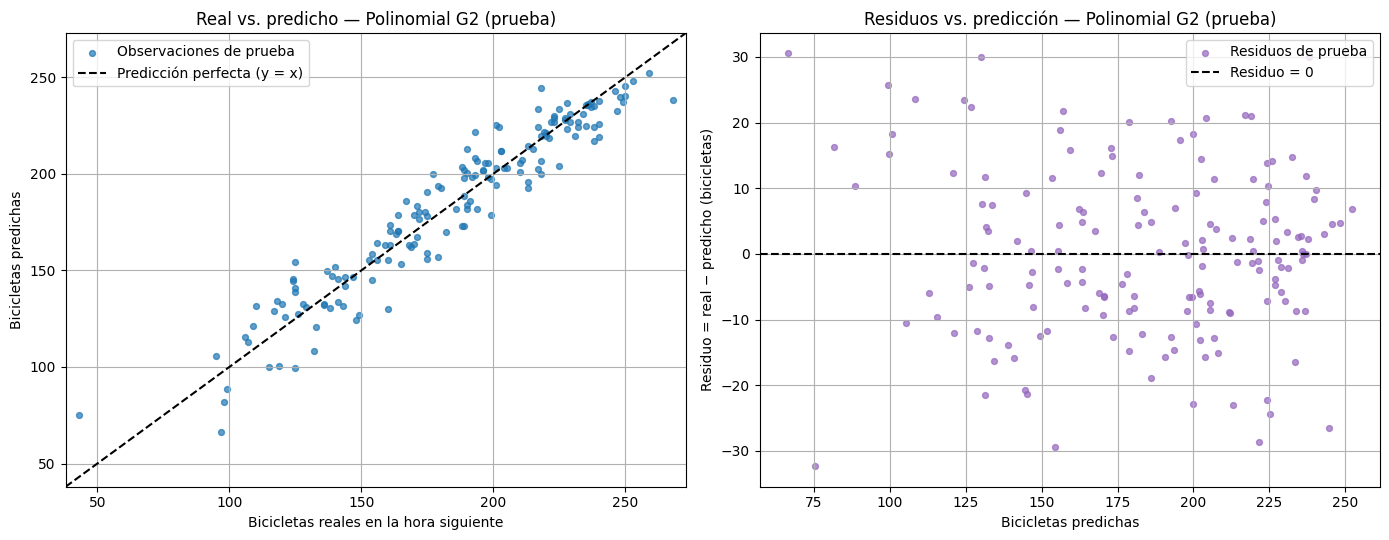

Residuos por cuartil de la predicción:


,n,media,desviacion
cuartil_prediccion,,,
"(66.473, 152.611]",41,0.38,15.64
"(152.611, 192.638]",41,-0.08,11.62
"(192.638, 220.376]",40,-0.26,12.12
"(220.376, 252.118]",41,-0.26,11.62


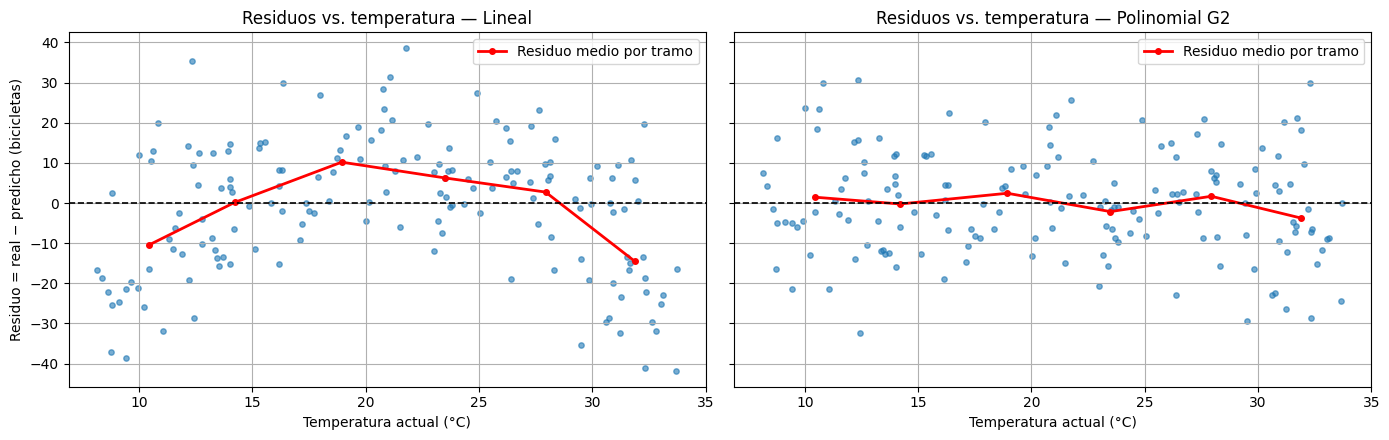

In [13]:
# Modelo con menor MAE en prueba y sus predicciones
mejor_reg = resultados_reg.loc[0, 'Modelo']
pred_mejor = predicciones_reg[mejor_reg]
residuo = yte_r.to_numpy() - pred_mejor
print(f'Modelo con menor MAE en prueba: {mejor_reg} (MAE = {resultados_reg.loc[0, "MAE"]:.2f} bicicletas)')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
# Real vs. predicho con la diagonal ideal y = x
ax = axes[0]
ax.scatter(yte_r, pred_mejor, s=18, alpha=0.7, label='Observaciones de prueba')
lims = [min(yte_r.min(), pred_mejor.min()) - 5, max(yte_r.max(), pred_mejor.max()) + 5]
ax.plot(lims, lims, 'k--', lw=1.5, label='Predicción perfecta (y = x)')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel('Bicicletas reales en la hora siguiente')
ax.set_ylabel('Bicicletas predichas')
ax.set_title(f'Real vs. predicho — {mejor_reg} (prueba)')
ax.legend()
# Residuos vs. predicción con línea horizontal en cero
ax = axes[1]
ax.scatter(pred_mejor, residuo, s=18, alpha=0.7, color='tab:purple', label='Residuos de prueba')
ax.axhline(0, color='k', ls='--', lw=1.5, label='Residuo = 0')
ax.set_xlabel('Bicicletas predichas')
ax.set_ylabel('Residuo = real − predicho (bicicletas)')
ax.set_title(f'Residuos vs. predicción — {mejor_reg} (prueba)')
ax.legend()
plt.tight_layout()
plt.show()

# Dispersión de los residuos por cuartil de la predicción (apoyo para evaluar heterocedasticidad)
print('Residuos por cuartil de la predicción:')
display(pd.DataFrame({'cuartil_prediccion': pd.qcut(pred_mejor, q=4), 'residuo': residuo})
        .groupby('cuartil_prediccion', observed=True)['residuo']
        .agg(n='size', media='mean', desviacion='std').round(2))

# Comparación de residuos según temperatura: lineal vs. mejor modelo (¿queda curvatura?)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, nombre in zip(axes, ['Lineal', mejor_reg]):
    res = yte_r.to_numpy() - predicciones_reg[nombre]
    ax.scatter(Xte_r['temperatura_c'], res, s=15, alpha=0.6)
    medias = (pd.DataFrame({'t': Xte_r['temperatura_c'].to_numpy(), 'r': res})
              .groupby(pd.qcut(Xte_r['temperatura_c'].to_numpy(), q=6), observed=True).mean())
    ax.plot(medias['t'], medias['r'], 'r-o', lw=2, ms=4, label='Residuo medio por tramo')
    ax.axhline(0, color='k', ls='--', lw=1.2)
    ax.set_xlabel('Temperatura actual (°C)')
    ax.set_title(f'Residuos vs. temperatura — {nombre}')
    ax.legend()
axes[0].set_ylabel('Residuo = real − predicho (bicicletas)')
plt.tight_layout()
plt.show()

### Apoyo para 1D: comportamiento fuera del rango de entrenamiento
Se fija la lluvia en su mediana y se recorre la temperatura desde −5 °C hasta 45 °C para observar cómo extrapola cada modelo.

Rango de entrenamiento: temperatura 8.05 a 33.99 °C | lluvia 0.06 a 15.00 mm/h
Lluvia fija en la mediana de entrenamiento: 2.96 mm/h


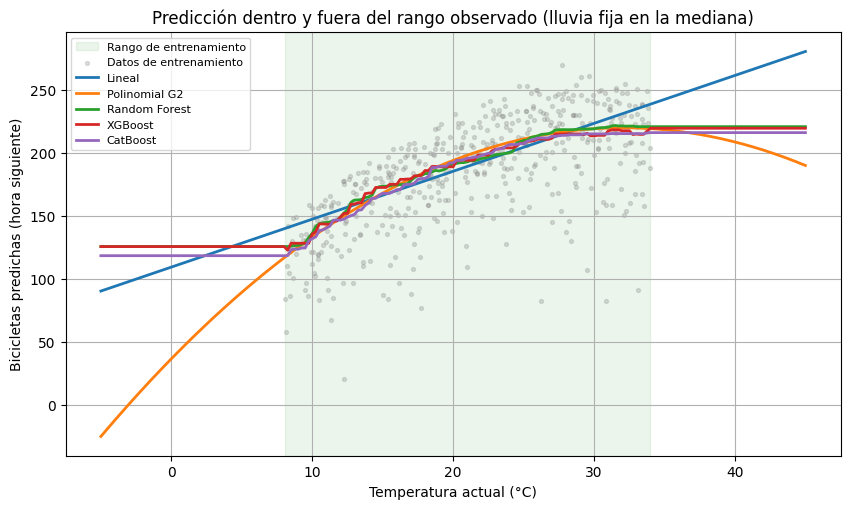

Bicicletas predichas en temperaturas seleccionadas:


,Lineal,Polinomial G2,Random Forest,XGBoost,CatBoost
temperatura_c (°C),,,,,
-5,90.3,-25.3,125.6,125.6,118.4
0,109.3,36.5,125.6,125.6,118.4
8,139.8,116.7,125.6,125.6,118.4
20,185.5,194.1,191.3,189.0,192.2
34,238.8,219.3,220.9,219.6,216.2
40,261.6,208.7,220.9,219.6,216.2
45,280.6,190.1,220.9,219.6,216.2


In [14]:
# ¿Qué predicen los modelos fuera del rango de temperatura visto en entrenamiento?
t_min, t_max = Xtr_r['temperatura_c'].min(), Xtr_r['temperatura_c'].max()
lluvia_fija = Xtr_r['lluvia_mm_h'].median()
print(f'Rango de entrenamiento: temperatura {t_min:.2f} a {t_max:.2f} °C | '
      f'lluvia {Xtr_r["lluvia_mm_h"].min():.2f} a {Xtr_r["lluvia_mm_h"].max():.2f} mm/h')
print(f'Lluvia fija en la mediana de entrenamiento: {lluvia_fija:.2f} mm/h')

malla = pd.DataFrame({'temperatura_c': np.linspace(-5, 45, 201), 'lluvia_mm_h': lluvia_fija})
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axvspan(t_min, t_max, color='green', alpha=0.08, label='Rango de entrenamiento')
ax.scatter(Xtr_r['temperatura_c'], ytr_r, s=8, alpha=0.25, color='gray', label='Datos de entrenamiento')
for nombre, modelo in modelos_reg.items():
    if nombre != 'Baseline (media)':
        ax.plot(malla['temperatura_c'], modelo.predict(malla), lw=2, label=nombre)
ax.set_xlabel('Temperatura actual (°C)')
ax.set_ylabel('Bicicletas predichas (hora siguiente)')
ax.set_title('Predicción dentro y fuera del rango observado (lluvia fija en la mediana)')
ax.legend(fontsize=8)
plt.show()

puntos = pd.DataFrame({'temperatura_c': [-5, 0, 8, 20, 34, 40, 45], 'lluvia_mm_h': lluvia_fija})
tabla_extrap = pd.DataFrame({nombre: modelo.predict(puntos) for nombre, modelo in modelos_reg.items()
                             if nombre != 'Baseline (media)'},
                            index=pd.Index(puntos['temperatura_c'], name='temperatura_c (°C)'))
print('Bicicletas predichas en temperaturas seleccionadas:')
display(tabla_extrap.astype(float).round(1))

### Tarea 1D. Respuestas breves
**1.** ¿Cuál es el modelo con menor MAE? ¿Se confirma la elección con RMSE y R²?

**Respuesta:** POLINOMIAL G2 obtiene el menor MAE (10.13 bicicletas) y también el menor RMSE (12.71) y el mayor R² (0.913), así que las tres métricas son consistentes. Sin embargo, CatBoost queda prácticamente empatado (MAE 10.14; RMSE 12.83; R² 0.911): 0.01 bicicletas de diferencia no es concluyente con una sola partición, y ante el empate, el polinomial es preferible por ser más simple e interpretable.

**2.** ¿Qué aporta el modelo polinomial frente al lineal? ¿Qué patrón observas en los residuos? ¿Existe evidencia visual de heterocedasticidad?

**Respuesta:** Los términos temperatura² (coef. −0.179) e interacción temperatura×lluvia capturan la SATURACION de la demanda: con lluvia mediana, +1 °C suma ≈ 8 bicicletas a 10 °C pero ≈ 1 a 30 °C. Con ello el MAE baja de 13.21 a 10.13 (−23 %) y R² sube de 0.855 a 0.913. Los residuos del lineal forman una U INVERTIDA frente a la temperatura (curvatura no capturada), mientras que los del polinomial quedan centrados en 0 sin patrón curvo. Hay evidencia de heterocedasticidad LEVE: la dispersión es algo mayor en las predicciones bajas (desv. 15.6 bicicletas en el primer cuartil vs. 11.6–12.1 en el resto), sin un embudo marcado.

**3.** ¿Qué precaución tendrías al extrapolar a temperaturas fuera del rango observado?

**Respuesta:** El entrenamiento cubre temperaturas de 8.05 a 33.99 °C; fuera de ese rango no hay datos que respalden ninguna forma funcional y los modelos divergen: a 45 °C el lineal predice 280.6 bicicletas (más que el máximo observado, 270), el polinomial 190.1 (la parábola cae) y los árboles quedan planos en ≈216–221; a −5 °C el polinomial llega a −25.3 bicicletas, un valor imposible. Usaría el modelo solo dentro del rango observado (marcando las entradas fuera de él), acotaría las predicciones a valores ≥ 0 y recolectaría datos de esas condiciones antes de extrapolar.

---
## Ejercicio 2 — Clasificación: entregas tardías
Una empresa logística quiere anticipar si una entrega se realizará fuera del plazo anunciado. Antes de iniciar el trayecto dispone de:

- `distancia_km` y `congestion_indice` (0–10): **X**.
- `entrega_tardia` (0: a tiempo, 1: tardía): **Y**, objetivo binario.
- **T**: resultado **al término de la entrega prevista**.

### Tarea 2A. Exploración y desbalance (5–10 min)
Calcula la proporción de entregas tardías. ¿Qué accuracy obtiene un clasificador que predice siempre la clase mayoritaria? ¿Por qué esa cifra puede ser engañosa?

,Variable,Rol,Unidad / codificación,Momento (T)
0,distancia_km,X1 · predictor,km,antes de la salida
1,congestion_indice,X2 · predictor,índice 0–10,antes de la salida
2,entrega_tardia,Y · objetivo binario,"0 = a tiempo, 1 = tardía",al término de la entrega


Tipos de dato y valores faltantes:


,tipo,faltantes
distancia_km,float64,0
congestion_indice,float64,0
entrega_tardia,int64,0


,count,mean,std,min,25%,50%,75%,max
distancia_km,750.0,21.71,11.63,2.0,11.27,21.62,31.33,41.99
congestion_indice,750.0,4.91,2.22,0.3,3.22,4.86,6.57,9.61
entrega_tardia,750.0,0.19,0.39,0.0,0.00,0.00,0.00,1.00


,n,proporción
entrega_tardia,,
0 · a tiempo,606,0.808
1 · tardía,144,0.192


Prevalencia de la clase 1 (entrega tardía): 0.192 (19.2%)
Accuracy al predecir siempre la clase mayoritaria (0 · a tiempo): 0.808
Recall de la clase 1 con esa estrategia: 0.000 -> no detecta ninguna entrega tardía
Media de cada predictor según la clase:


,distancia_km,congestion_indice
entrega_tardia,,
0,20.11,4.59
1,28.43,6.26


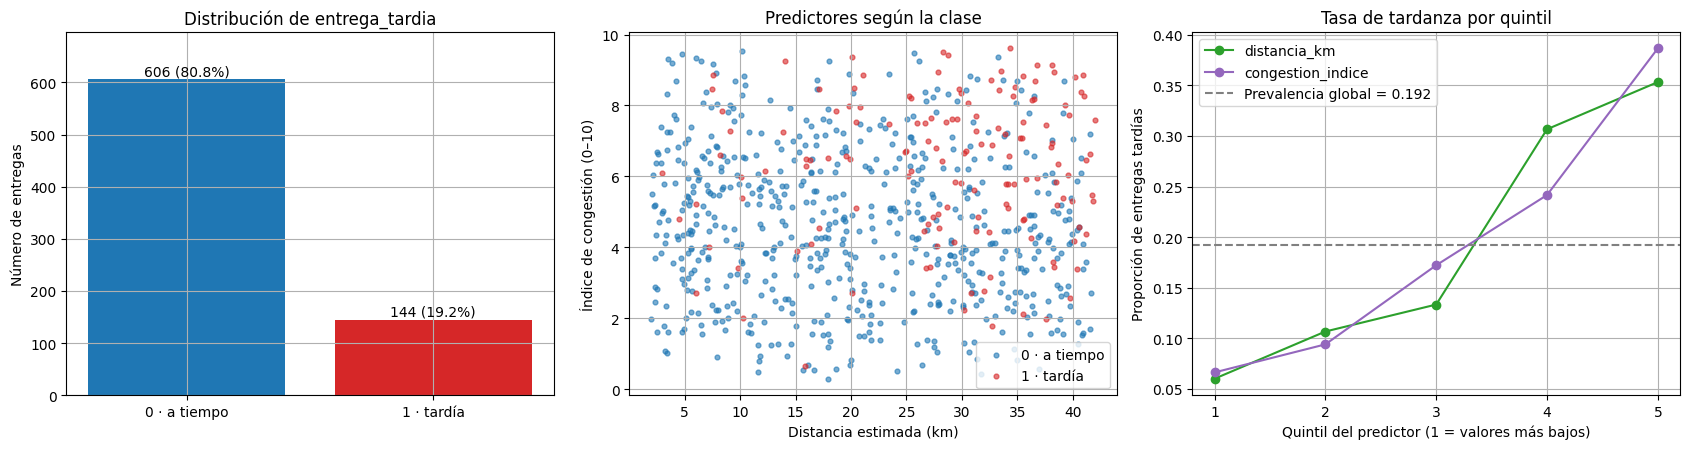

In [15]:
# Descripción de X, Y y T en el problema de clasificación
roles_cls = pd.DataFrame({
    'Variable': ['distancia_km', 'congestion_indice', 'entrega_tardia'],
    'Rol': ['X1 · predictor', 'X2 · predictor', 'Y · objetivo binario'],
    'Unidad / codificación': ['km', 'índice 0–10', '0 = a tiempo, 1 = tardía'],
    'Momento (T)': ['antes de la salida', 'antes de la salida', 'al término de la entrega']
})
display(roles_cls)

print('Tipos de dato y valores faltantes:')
display(pd.DataFrame({'tipo': df_cls.dtypes.astype(str), 'faltantes': df_cls.isna().sum()}))
display(df_cls.describe().T.round(2))

# Conteo de clases y prevalencia
conteo = df_cls['entrega_tardia'].value_counts().sort_index()
display(pd.DataFrame({'n': conteo, 'proporción': (conteo / conteo.sum()).round(3)})
        .rename(index={0: '0 · a tiempo', 1: '1 · tardía'}))
prevalencia = df_cls['entrega_tardia'].mean()
acc_mayoritaria = max(prevalencia, 1 - prevalencia)
print(f'Prevalencia de la clase 1 (entrega tardía): {prevalencia:.3f} ({prevalencia:.1%})')
print(f'Accuracy al predecir siempre la clase mayoritaria (0 · a tiempo): {acc_mayoritaria:.3f}')
print('Recall de la clase 1 con esa estrategia: 0.000 -> no detecta ninguna entrega tardía')

print('Media de cada predictor según la clase:')
display(df_cls.groupby('entrega_tardia')[['distancia_km', 'congestion_indice']].mean().round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
# Distribución de la clase
ax = axes[0]
ax.bar(['0 · a tiempo', '1 · tardía'], conteo.values, color=['tab:blue', 'tab:red'])
for i, v in enumerate(conteo.values):
    ax.text(i, v + 8, f'{v} ({v / conteo.sum():.1%})', ha='center')
ax.set_ylim(0, conteo.max() * 1.15)
ax.set_ylabel('Número de entregas')
ax.set_title('Distribución de entrega_tardia')
# Predictores coloreados por clase
ax = axes[1]
for clase, color, etiqueta in [(0, 'tab:blue', '0 · a tiempo'), (1, 'tab:red', '1 · tardía')]:
    sub = df_cls[df_cls['entrega_tardia'] == clase]
    ax.scatter(sub['distancia_km'], sub['congestion_indice'], s=12, alpha=0.6, color=color, label=etiqueta)
ax.set_xlabel('Distancia estimada (km)')
ax.set_ylabel('Índice de congestión (0–10)')
ax.set_title('Predictores según la clase')
ax.legend()
# Tasa de entregas tardías por quintil de cada predictor
ax = axes[2]
for col, color in [('distancia_km', 'tab:green'), ('congestion_indice', 'tab:purple')]:
    tasa = df_cls.groupby(pd.qcut(df_cls[col], q=5, labels=[1, 2, 3, 4, 5]), observed=True)['entrega_tardia'].mean()
    ax.plot(tasa.index.astype(int), tasa.values, '-o', color=color, label=col)
ax.axhline(prevalencia, color='gray', ls='--', label=f'Prevalencia global = {prevalencia:.3f}')
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel('Quintil del predictor (1 = valores más bajos)')
ax.set_ylabel('Proporción de entregas tardías')
ax.set_title('Tasa de tardanza por quintil')
ax.legend()
plt.tight_layout()
plt.show()

**Observación 2A:** La prevalencia de entregas tardías es **19.2 %** (144 de 750), un desbalance moderado de ≈ 4 entregas a tiempo por cada tardía. Predecir siempre la clase mayoritaria («a tiempo») obtiene accuracy **0.808** sin detectar ninguna tardía (recall = 0): la cifra parece buena, pero el modelo es inútil para el objetivo, porque todos sus errores son falsos negativos, justo el error que se quiere evitar. Por eso 0.808 es la referencia mínima de accuracy y conviene evaluar con métricas de la clase 1 (precision, recall, F1 y AP, cuya línea base es la prevalencia). Las tardías se asocian a mayor distancia (28.4 vs. 20.1 km) y congestión (6.26 vs. 4.59), y la tasa de tardanza sube de ≈ 6 % en el quintil más bajo a 35–39 % en el más alto; aun así las clases se superponen bastante, por lo que no cabe esperar una separación perfecta.

### Tarea 2B. Entrena clasificadores (15 min)
Utiliza una partición **75%/25% estratificada**. Compara: baseline mayoritaria, regresión logística, Random Forest y los modelos boosting disponibles. Calcula `accuracy`, `precision`, `recall`, `F1`, `ROC AUC` y `AP` (*Average Precision*, resumen de la curva precision–recall). Define clase positiva como `1`.

**Atención:** `ROC AUC` y `AP` se calculan con **probabilidades o puntajes**, no con la etiqueta 0/1.

In [16]:
features_cls = ['distancia_km', 'congestion_indice']
X_cls = df_cls[features_cls]
y_cls = df_cls['entrega_tardia']
Xtr_c, Xte_c, ytr_c, yte_c = train_test_split(
    X_cls, y_cls, test_size=0.25, random_state=42, stratify=y_cls)

modelos_cls = {
    'Baseline (mayoría)': DummyClassifier(strategy='most_frequent'),
    'Logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=5,
                                            min_samples_leaf=3, random_state=42,n_jobs=-1)
}
if XGBClassifier is not None:
    modelos_cls['XGBoost'] = XGBClassifier(n_estimators=120, max_depth=3,
                                          learning_rate=0.06, eval_metric='logloss',
                                          random_state=42, n_jobs=2)
if CatBoostClassifier is not None:
    modelos_cls['CatBoost'] = CatBoostClassifier(iterations=120, depth=4,
                                                learning_rate=0.06, verbose=False,
                                                random_seed=42, thread_count=2)

# Entrenar modelos, obtener probabilidades de la clase 1 y
# clases predichas con umbral 0.5; calcular todas las métricas pedidas.
from sklearn.metrics import balanced_accuracy_score

umbral = 0.50
filas_cls = []
probabilidades_cls = {}
for nombre, modelo in modelos_cls.items():
    modelo.fit(Xtr_c, ytr_c)
    proba = modelo.predict_proba(Xte_c)[:, 1]      # P(entrega_tardia = 1 | X)
    pred = (proba >= umbral).astype(int)           # etiqueta con umbral 0.50
    probabilidades_cls[nombre] = proba
    filas_cls.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(yte_c, pred),
        'Precision': precision_score(yte_c, pred, pos_label=1, zero_division=0),
        'Recall': recall_score(yte_c, pred, pos_label=1, zero_division=0),
        'F1': f1_score(yte_c, pred, pos_label=1, zero_division=0),
        'ROC AUC': roc_auc_score(yte_c, proba),               # usa probabilidades
        'AP': average_precision_score(yte_c, proba),          # usa probabilidades
        'Balanced acc.': balanced_accuracy_score(yte_c, pred)  # referencia adicional
    })

# Tabla de clasificación ordenada por AP (descendente)
resultados_cls = pd.DataFrame(filas_cls).sort_values('AP', ascending=False).reset_index(drop=True)
print(f'Entrenamiento: {len(Xtr_c)} obs. | Prueba: {len(Xte_c)} obs. '
      f'({int(yte_c.sum())} tardías) | Prevalencia clase 1 -> train: {ytr_c.mean():.3f}, test: {yte_c.mean():.3f}')
print('Accuracy, precision, recall, F1 y balanced acc. con umbral 0.50; ROC AUC y AP con probabilidades.')
display(resultados_cls.round(3))

Entrenamiento: 562 obs. | Prueba: 188 obs. (36 tardías) | Prevalencia clase 1 -> train: 0.192, test: 0.191
Accuracy, precision, recall, F1 y balanced acc. con umbral 0.50; ROC AUC y AP con probabilidades.


,Modelo,Accuracy,Precision,Recall,F1,ROC AUC,AP,Balanced acc.
0,Logística,0.840,0.688,0.306,0.423,0.792,0.567,0.636
1,CatBoost,0.824,0.560,0.389,0.459,0.762,0.557,0.658
2,Random Forest,0.819,0.538,0.389,0.452,0.727,0.466,0.655
3,XGBoost,0.814,0.517,0.417,0.462,0.748,0.431,0.662
4,Baseline (mayoría),0.809,0.000,0.000,0.000,0.500,0.191,0.500


### Tarea 2C. Matriz de confusión y curvas (10 min)
Para uno de los modelos distintos de la línea base, dibuja la **matriz de confusión** con umbral `0.50`, la **curva ROC** y la **curva Precision–Recall**. Añade a la gráfica PR una línea horizontal con la prevalencia positiva en prueba.

Modelo analizado: Logística


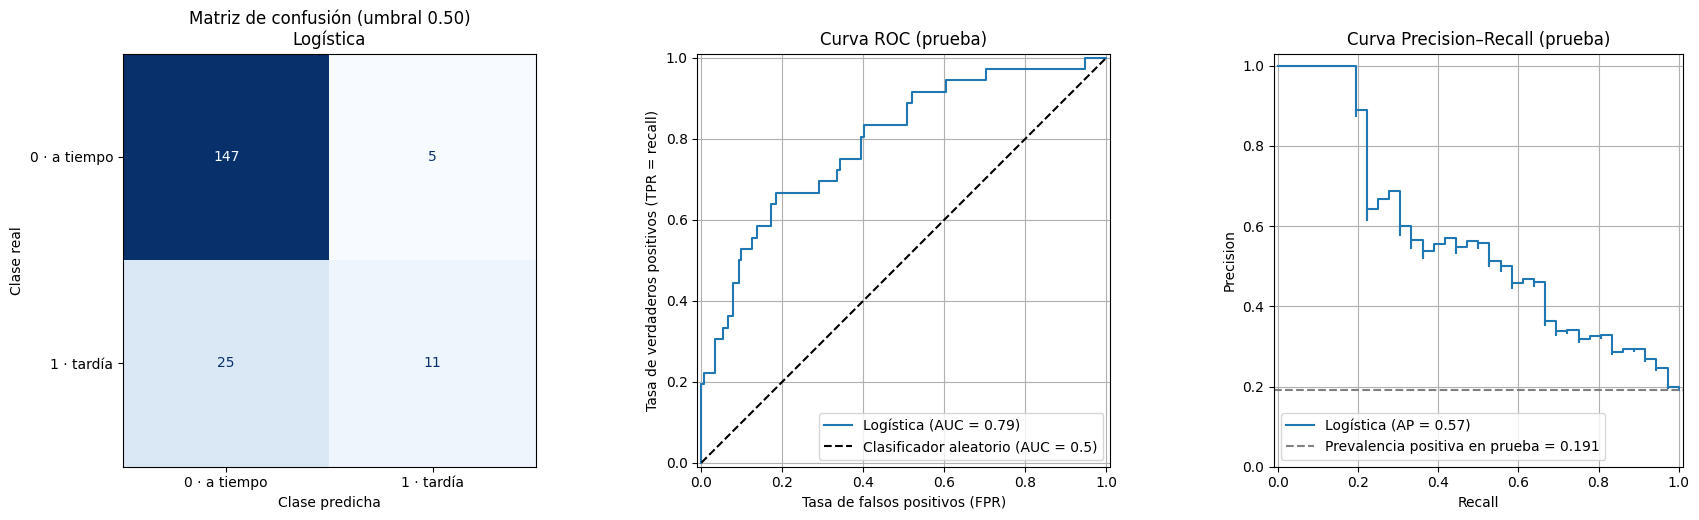

In [17]:
# Se escoge el modelo con mayor AP distinto de la línea base
modelo_elegido = resultados_cls.loc[resultados_cls['Modelo'] != 'Baseline (mayoría)', 'Modelo'].iloc[0]
proba_elegido = probabilidades_cls[modelo_elegido]
pred_elegido = (proba_elegido >= 0.50).astype(int)
prevalencia_test = yte_c.mean()
print(f'Modelo analizado: {modelo_elegido}')

fig, axes = plt.subplots(1, 3, figsize=(18, 5.3))
# Matriz de confusión con umbral 0.50 -> [[TN, FP], [FN, TP]]
ConfusionMatrixDisplay.from_predictions(yte_c, pred_elegido, labels=[0, 1],
                                        display_labels=['0 · a tiempo', '1 · tardía'],
                                        cmap='Blues', colorbar=False, ax=axes[0])
axes[0].grid(False)
axes[0].set_xlabel('Clase predicha')
axes[0].set_ylabel('Clase real')
axes[0].set_title(f'Matriz de confusión (umbral 0.50)\n{modelo_elegido}')
# Curva ROC con la referencia de un clasificador aleatorio
RocCurveDisplay.from_predictions(yte_c, proba_elegido, name=modelo_elegido, plot_chance_level=True,
                                 chance_level_kw={'label': 'Clasificador aleatorio (AUC = 0.5)'},
                                 ax=axes[1])
axes[1].set_xlabel('Tasa de falsos positivos (FPR)')
axes[1].set_ylabel('Tasa de verdaderos positivos (TPR = recall)')
axes[1].set_title('Curva ROC (prueba)')
axes[1].legend(loc='lower right')
# Curva Precision–Recall con la prevalencia positiva como línea base
PrecisionRecallDisplay.from_predictions(yte_c, proba_elegido, name=modelo_elegido, ax=axes[2])
axes[2].axhline(prevalencia_test, color='gray', ls='--',
                label=f'Prevalencia positiva en prueba = {prevalencia_test:.3f}')
axes[2].set_ylim(0, 1.03)
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].set_title('Curva Precision–Recall (prueba)')
axes[2].legend(loc='lower left')
plt.tight_layout()
plt.show()

### Tarea 2D. Efecto del umbral (5–10 min)
Para el mismo modelo, compara umbrales `0.30` y `0.50`. Reporta **FP, FN, precision y recall**. Supón que perder una entrega tardía (FN) es especialmente costoso: ¿qué umbral defenderías? Justifica usando resultados, no solo intuición.

Modelo: Logística | entregas tardías reales en prueba: 36 de 188


,TP,FP,FN,TN,Alertas (TP+FP),Precision,Recall,F1,Accuracy
Umbral,,,,,,,,,
0.3,19,18,17,134,37,0.514,0.528,0.521,0.814
0.5,11,5,25,147,16,0.688,0.306,0.423,0.840


Al bajar el umbral de 0.50 a 0.30: FN -8 | FP +13 | recall +0.222 | precision -0.174


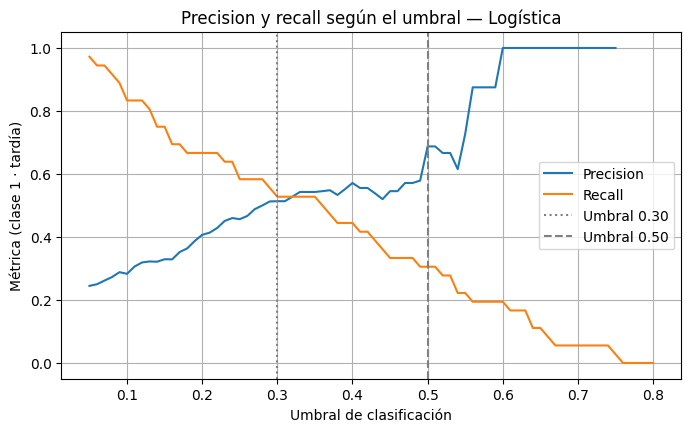

In [18]:
# Comparación de umbrales 0.30 y 0.50 para el mismo modelo
filas_umbral = []
for u in [0.30, 0.50]:
    pred_u = (proba_elegido >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(yte_c, pred_u, labels=[0, 1]).ravel()
    filas_umbral.append({
        'Umbral': u, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
        'Alertas (TP+FP)': tp + fp,
        'Precision': precision_score(yte_c, pred_u, zero_division=0),
        'Recall': recall_score(yte_c, pred_u, zero_division=0),
        'F1': f1_score(yte_c, pred_u, zero_division=0),
        'Accuracy': accuracy_score(yte_c, pred_u)
    })
tabla_umbral = pd.DataFrame(filas_umbral).set_index('Umbral')
print(f'Modelo: {modelo_elegido} | entregas tardías reales en prueba: {int(yte_c.sum())} de {len(yte_c)}')
display(tabla_umbral.round(3))

dif = tabla_umbral.loc[0.30] - tabla_umbral.loc[0.50]
print(f'Al bajar el umbral de 0.50 a 0.30: FN {dif["FN"]:+.0f} | FP {dif["FP"]:+.0f} | '
      f'recall {dif["Recall"]:+.3f} | precision {dif["Precision"]:+.3f}')

# Precision y recall a lo largo de distintos umbrales
# (precision queda sin definir cuando el umbral no deja ninguna alerta)
umbrales = np.round(np.arange(0.05, 0.81, 0.01), 2)
prec_u = [precision_score(yte_c, (proba_elegido >= u).astype(int), zero_division=np.nan) for u in umbrales]
rec_u = [recall_score(yte_c, (proba_elegido >= u).astype(int), zero_division=0) for u in umbrales]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(umbrales, prec_u, label='Precision')
ax.plot(umbrales, rec_u, label='Recall')
for u, estilo in [(0.30, ':'), (0.50, '--')]:
    ax.axvline(u, color='gray', ls=estilo, label=f'Umbral {u:.2f}')
ax.set_xlabel('Umbral de clasificación')
ax.set_ylabel('Métrica (clase 1 · tardía)')
ax.set_title(f'Precision y recall según el umbral — {modelo_elegido}')
ax.legend(loc='center right')
plt.show()

**Decisión 2D:** Si omitir una entrega tardía es costoso, defendería el umbral 0.30. Con él los FN bajan de 25 a 17 y el recall pasa de 0.306 a 0.528, mientras la precision se mantiene en 0.514 (aproximadamente una de cada dos alertas es real, casi el triple de la prevalencia de 0.191). El precio son 13 falsas alarmas adicionales (FP: 5 → 18; alertas: 16 → 37) y un accuracy algo menor (0.840 → 0.814), costo aceptable si cada tardía no anticipada pesa más que ≈ 1.6 falsas alarmas (13 FP extra / 8 FN evitados). Aun así, 17 de 36 tardías siguen sin detectarse; el umbral definitivo debería fijarse con los costos reales del negocio y sobre datos de validación, no ajustándolo repetidamente con el conjunto de prueba.

### Tarea 2E. Respuestas breves
**1.** ¿Por qué un accuracy alto no necesariamente representa un buen clasificador en estos datos?

**Respuesta:** Porque el 80.8 % de las entregas llega a tiempo: la línea base que nunca predice tardanza ya logra accuracy 0.809 en prueba con recall 0. La logística (umbral 0.50) sube solo a 0.840, aunque detecta apenas 11 de 36 tardías (recall 0.306), y al bajar el umbral a 0.30 detecta 8 tardías más pero su accuracy *baja* a 0.814. El accuracy está dominado por los verdaderos negativos de la clase mayoritaria y no refleja la detección de la clase que interesa; por eso se privilegian recall, precision, F1 y AP (cuya referencia es la prevalencia, 0.191).

**2.** Compara la clasificación logística con Random Forest y boosting. ¿Qué modelo priorizarías si importa detectar entregas tardías? Considera recall, precision y AP.

**Respuesta:** La LOGISTICA ordena mejor los casos (ROC AUC 0.792; AP 0.567), seguida de cerca por CatBoost (0.762; 0.557) y más atrás por Random Forest (0.727; 0.466) y XGBoost (0.748; 0.431). Con umbral 0.50 los árboles muestran más recall (0.39–0.42 frente a 0.31) pero menos precision (0.52–0.56 frente a 0.69); esa diferencia depende de dónde corta el umbral cada modelo, no de su capacidad de separar las clases. Como el riesgo crece de forma monótona con distancia y congestión (2A), una frontera lineal resulta suficiente y los árboles agregan varianza con solo 108 tardías en entrenamiento. Priorizaría la logística con umbral reducido (0.30: recall 0.528, precision 0.514), teniendo presente que su ventaja sobre CatBoost (0.01 de AP) no es concluyente con 36 positivos en prueba.

**3.** ¿Cómo cambia el número de falsos negativos al mover el umbral? ¿Cuál es el costo de ese cambio en falsas alarmas?

**Respuesta:** Al bajar el umbral de 0.50 a 0.30, los FN caen de 25 a 17 (−8) y el recall sube de 0.306 a 0.528; a cambio, los FP suben de 5 a 18 (+13), las alertas pasan de 16 a 37 y la precision baja de 0.688 a 0.514. Cada tardía adicional detectada cuesta ≈ 1.6 falsas alarmas (13/8), así que el cambio conviene cuando un FN cuesta más de ≈ 1.6 veces un FP, condición razonable si omitir una tardía es especialmente costoso.

---
## Cierre: conclusiones y entregable
Escribe un párrafo de **4 a 6 líneas** que compare la elección de métricas en regresión y clasificación. Incluye al menos una limitación de las conclusiones obtenidas al utilizar una sola partición train/test.

**Conclusión:** En regresión el error es continuo (MAE y RMSE en bicicletas; $R^2$ respecto a la media), y los residuos revelaron curvatura omitida por el modelo lineal y leve heterocedasticidad. En clasificación las probabilidades se vuelven etiquetas mediante un umbral, separando el error en FP y FN con costos disímiles; ante un 19% de tardías, el accuracy es engañoso y exige evaluar matriz de confusión, precision, recall, F1, ROC AUC y AP frente a la prevalencia. La limitación clave es el uso de una sola partición 75/25 (semilla 42, 163 pruebas en regresión y 36 tardías en clasificación): ventajas estrechas como Polinomial vs. CatBoost (0.01 de MAE) o Logística vs. CatBoost (0.01 de AP) podrían revertirse con otra semilla, requiriendo validación cruzada o bootstrap para medir la incertidumbre.   

**Antes de entregar:** ejecuta todas las celdas en orden, revisa que aparezcan tablas y gráficos, y entrega el notebook con las respuestas guardadas.